<a href="https://colab.research.google.com/github/emisseldine/MisselBooks/blob/main/LinearAlgebra/workbooks/regular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center>
<p style="text-align:center">
    <a href="https://raw.githubusercontent.com/emisseldine/OpenLinear/main/BackMatter/logo.png" target="_blank">
    <img src="https://raw.githubusercontent.com/emisseldine/OpenLinear/main/BackMatter/logo.png" width="200" alt="Missel Books Logo">
    </a>
</p>


# 4.8 Regularization
</center>

###For Exercises 1-3, interpolate the  function $f$ through the given points with a regularization coefficient $\lambda$.


---


*An example is provided in Exercise 0. To execute your code, hit the play/execute/run button or Shift+Enter.*


0.  $f(x) = a_1x+a_0$, $\lambda=0.25$


 
1.426 x + 0.8372 
RMS error = 5.52% 
coeff norm = 1.6539082608489406



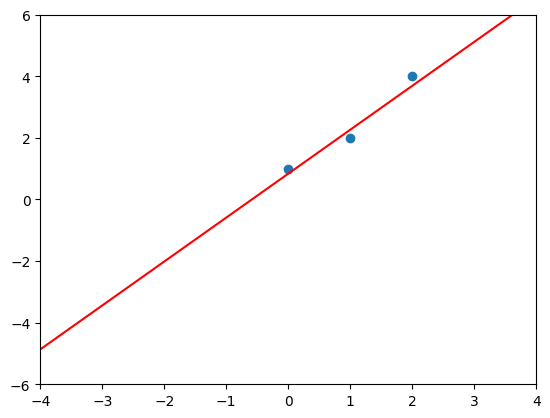

In [1]:
import numpy as np

RMS_error = lambda f,x,y: round(100*np.sqrt(np.mean((y-np.polyval(f,x))**2))/np.linalg.norm(y),2)

def data_fit_regular(X, y, lamb):
    m,n = X.shape
    A = np.concatenate((np.array(X),np.sqrt(lamb)*np.identity(n)))
    b = np.concatenate((np.array(y),np.zeros(n)))
    return np.linalg.lstsq(A,b, rcond=None)[0]

### EXERCISE 0#######################################
# interpolate the function f(x) = a_0 + a_1x through the given points.
points = np.array([[0,1],[1,2],[2,4]])
x = points[:,0]                   # just the x-coordinates
y= points[:,1]                    # just the y-coordinates

f = data_fit_regular(np.vander(x,2),y,0.25)
print(np.poly1d(f),f"\nRMS error = {RMS_error(f,x,y)}%",f"\ncoeff norm = {np.linalg.norm(f)}\n")

#Graph Scatterplot
import matplotlib.pyplot as plt

t = np.linspace(-4,4,100)
plt.xlim(-4,4)
plt.ylim(-6,6)
plt.scatter(x, y)
plt.plot(t,np.poly1d(f)(t),'r')
plt.show()

1.  $f(x)=a_2x^2+a_1x+a_0$, $\lambda=0.2$


In [ ]:
### EXERCISE 1#######################################
# interpolate the function f(x) = a_0 + a_1x + a_2x^2 through the given points.
points = np.array([[-1,1],[0,0],[1,2],[2,5]])
x = points[:,0]                   # just the x-coordinates
y= points[:,1]                    # just the y-coordinates

#f = #construct your model here. You may need to construct the matrix A in the line above.
print(np.poly1d(f),f"\nRMS error = {RMS_error(f,x,y)}%",f"\ncoeff norm = {np.linalg.norm(f)}\n")

#Graph Scatterplot
t = np.linspace(-4,4,100)
plt.xlim(-4,4)
plt.ylim(-3,10)
plt.scatter(x, y)
plt.plot(t,np.poly1d(f)(t),'r')
plt.show()

<details><summary>Click here for the solution</summary>

$f(x) = 0.9861 x^2 + 0.4038 x + 0.3038  $
```Python
RMS error = 4.1%
coeff norm = 1.1080237983385017
```

</details>

2.  $f(x)=a_5x^5+a_4x^4+a_3x^3+a_2x^2+a_1x+a_0$, $\lambda=0.1$

In [ ]:
### EXERCISE 2#######################################
points = np.array([[-2,231],[-1,19],[0,5],[1,9],[2,19],[3,-169],
                   [-1.5,100],[-0.5,20],[0.5,12],[2.5,0],[3.5,-25]])
x = points[:,0]
y = points[:,1]

f = #construct your model here. You may need to construct the matrix A in the line above.
print(np.poly1d(f),f"\nRMS error = {RMS_error(f,x,y)}%",f"\ncoeff norm = {np.linalg.norm(f)}\n")

#Graph Scatterplot
t = np.linspace(-3,4,100)
plt.axis([-3,4,-200,300])
plt.scatter(x,y)
plt.plot(t,np.poly1d(f)(t),'r')
plt.show()

<details><summary>Click here for the solution</summary>

$f(x) = 2.501 x^5 - 4.385 x^4 - 32.74 x^3 + 47.38 x^2 + 36.47 x - 5.539  $
```Python
RMS error = 10.37%
coeff norm = 68.5737975372278
```

</details>

4.  $f(x)=\dfrac{a_2x^2+a_1x+a_0}{b_2x^2+b_1x+1}$


In [ ]:
### EXERCISE 4#######################################
points = np.array([[-2,12/11],[-1,3/2],[0,2],[1,0],[2,0],
                   [-1.5,10/3],[-0.5,20/15],[0.5,-12/5],[2.5,-11/3],[3.5,-25/7]])
x = points[:,0]
y = points[:,1]
n=2

#f = #construct your model here. You may need to construct the matrix A in the line above.
numer = f[:n+1]
denom = np.concatenate((f[n+1:],[1]))
print(np.poly1d(numer),"/\n",np.poly1d(denom),f"\nRMS error = {RMS_error(f,x,y)}%",f"\ncoeff norm = {np.linalg.norm(f)}\n")

#Graph Scatterplot
plt.axis([-3,4,-10,10])
plt.scatter(x,y)
plt.plot(t, np.polyval(numer,t) / np.polyval(denom,t), 'r')
plt.show()

<details><summary>Click here for the solution</summary>

$f(x)=\dfrac{0.1541 x^2 - 0.6662 x + 0.366}{-0.08011 x - 0.05146 x + 1 }$
</details>

---
*When completed, convert your .ipynb notebook into an .html webpage and upload it to the course's learning management system, e.g. Canvas.*
<details><summary> Instructions to convert to .html </summary>

1. *Download the .ipynb notebook, which you want to convert, on your local computer.*
2. *Run the code below to upload the .ipynb notebook.*
3. *The .html webpage will be downloaded automatically on your local machine.*

</details>

In [ ]:
from google.colab import files
f = files.upload()
import subprocess
file0 = list(f.keys())[0]
_ = subprocess.run(["pip", "install", "nbconvert"])
_ = subprocess.run(["jupyter", "nbconvert", file0, "--to", "html"])
files.download(file0[:-5]+"html")



---
<center>

##### This Python workbook was produced for [Linear Algebra Done Openly](https://github.com/emisseldine/MisselBooks/tree/main/LinearAlgebra) by Dr. Andrew Misseldine (2026).
<p style="text-align:center">
    <a href="https://raw.githubusercontent.com/emisseldine/OpenLinear/main/BackMatter/logo.png" target="_blank">
    <img src="https://raw.githubusercontent.com/emisseldine/OpenLinear/main/BackMatter/logo.png" width="200" alt="Missel Books Logo">
    </a>
</p>
</center>